In [1]:
import sys, os
from dataclasses import dataclass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch, Rectangle

from app.services.coverage_dp import solve_coverage, solve_coverage_batch, allocate_budget, solve_allocated

## 1. Example (single L)

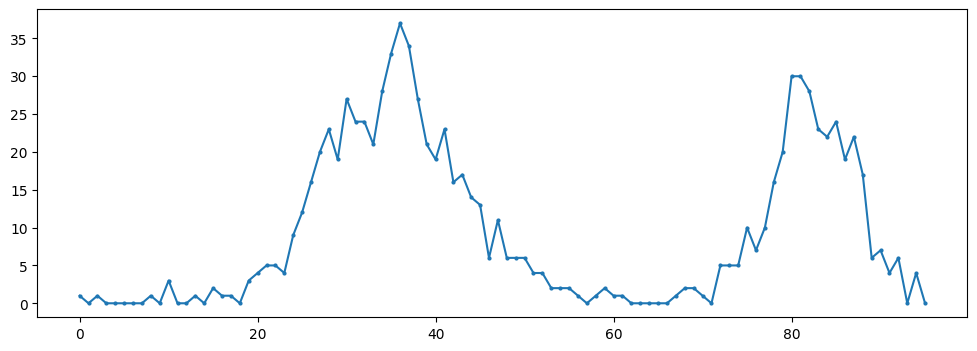

In [2]:
def _synthetic_day(seed, T=96):
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    lam = np.full(T, 0.5)                           # baseline: pax / 15 min
    for _ in range(rng.integers(1, 7)):             # 1-2 peaks
        center, width, height = rng.uniform(10, T - 10), rng.uniform(4, 9), rng.uniform(6, 30)
        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return rng.poisson(lam).astype(int).tolist()

plt.figure(figsize=(12, 4))
arrivals = _synthetic_day(seed=1)
plt.plot(arrivals, marker=".", markersize=4)
plt.show()

In [3]:
def arrivals_to_demand_grid(arrivals, mean_processing_rate, unit_time, freq_minutes=15):
    """
    arrivals             : (T,) pax arriving in each slot
    mean_processing_rate : pax per hour processed by one counter
    unit_time            : time unit for the processing rate
    returns (D, required_exact)
        D              : (n_counters, T) float in [0, 1]; row c = c-th counter
        required_exact : (T,) counters needed per slot, as a float
    """
    a = np.asarray(arrivals, dtype=np.float64)
    if a.ndim != 1:
        raise ValueError("arrivals must be 1-D (T,)")
    if mean_processing_rate <= 0 or freq_minutes <= 0:
        raise ValueError("mean_processing_rate and freq_minutes must be > 0")
    pax_per_counter_bin = mean_processing_rate * (freq_minutes / unit_time)
    required_exact = a / pax_per_counter_bin                       # counters needed, float
    n_counters = int(np.ceil(required_exact.max()))
    if n_counters == 0:
        raise ValueError("no arrivals: the demand grid would be empty")
    layers = np.arange(n_counters)[:, None]                        # counter index 0..n-1
    D = np.clip(required_exact[None, :] - layers, 0.0, 1.0)        # (n_counters, T)
    return D, required_exact

MEAN_PROCESSING_RATE = 10
D, required_exact = arrivals_to_demand_grid(arrivals, MEAN_PROCESSING_RATE, unit_time=15)

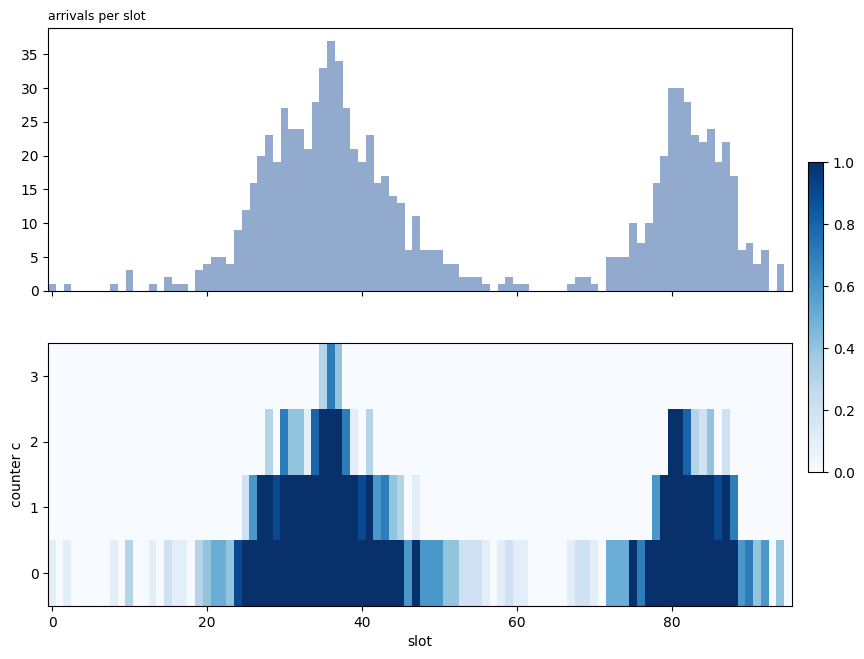

In [ ]:
def plot_grid(arrivals, required_exact, D, freq_minutes=15):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter c")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

plot_grid(arrivals, required_exact, D)
plt.show()

In [19]:
L, alpha = 12, 0
curve = solve_coverage_batch(D, L, alpha, return_curve=True)

K_total = 20
g = allocate_budget(curve, K_total)

sols = solve_allocated(D, L, alpha, g)

print(f"{'ctr':>3} {'k':>3} {'value':>8} | {'inside':>7} {'outside':>8} {'missed':>7}")
for i, s in enumerate(sols):
    assert abs(s.value - (s.inside - alpha * s.outside)) < 1e-9          # objective identity
    assert abs(s.inside + s.missed - D[i].sum()) < 1e-9                  # all demand is served or missed
    print(f"{i:>3} {g.k[i]:>3} {s.value:>8.2f} | {s.inside:>7.2f} {s.outside:>8.2f} {s.missed:>7.2f}")

ctr   k    value |  inside  outside  missed
  0   8    49.00 |   49.00    47.00    0.00
  1   3    27.90 |   27.90     8.10    0.00
  2   3    10.70 |   10.70    25.30    0.00
  3   1     1.40 |    1.40    10.60    0.00


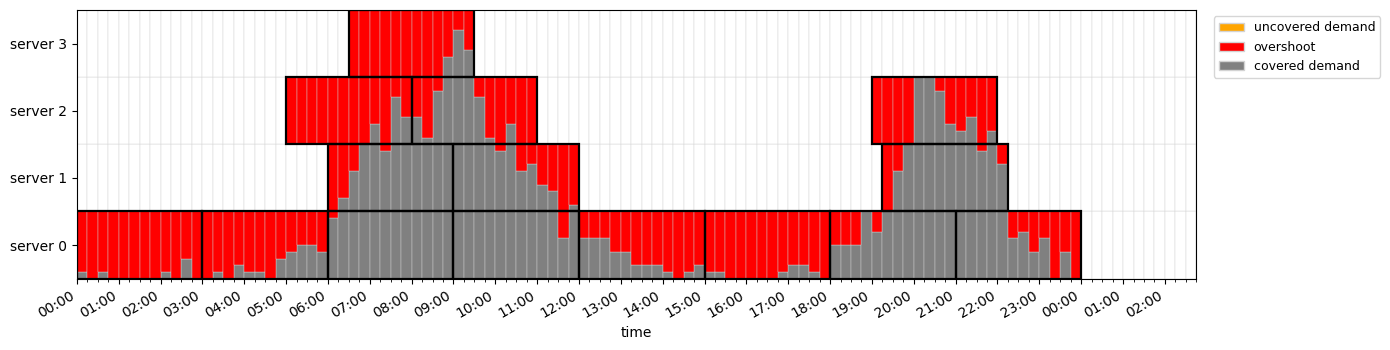

In [20]:
def plot_grid_overlay(grid, alloc, time_values, bin_minutes=None, row_label="server", L=None,
                      block_gap=0.15):
    D = np.asarray(grid, dtype=np.float64)
    if isinstance(alloc, (list, tuple)):                     # list of Solution
        cov = np.vstack([np.asarray(s.coverage, dtype=bool) for s in alloc])
    else:                                                    # bool matrix (n_rows, T)
        cov = np.asarray(alloc, dtype=bool)
    if cov.shape[0] != D.shape[0] or cov.shape[1] < D.shape[1]:
        raise ValueError(f"alloc shape {cov.shape} incompatible with grid shape {D.shape}")
    real_bins = D.shape[1]
    extra = cov.shape[1] - real_bins                         # overhang slots after the end of the day
    if extra:
        D = np.pad(D, ((0, 0), (0, extra)))

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape
    if bin_minutes is None:
        bin_minutes = (
            (time_values.iloc[1] - time_values.iloc[0]).total_seconds() / 60
            if len(time_values) > 1 else 15
        )
    if extra and len(time_values) == real_bins:              # extend the time axis over the overhang
        more = time_values.iloc[-1] + pd.to_timedelta(np.arange(1, extra + 1) * bin_minutes, unit="min")
        time_values = pd.concat([time_values, pd.Series(more)], ignore_index=True)
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")
    if bin_minutes is None:
        bin_minutes = (
            (time_values.iloc[1] - time_values.iloc[0]).total_seconds() / 60
            if len(time_values) > 1 else 15
        )

    x0 = mdates.date2num(time_values)                        # left edge of each bin
    width = bin_minutes / (24 * 60)                          # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(14, 0.4 * n_rows + 2))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        # bottom part: demand  (grey if covered, orange if not)
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        # top part: capacity not needed  (red if covered = waste, white if not)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    # one outlined rectangle per shift block
    if isinstance(alloc, (list, tuple)) and L is not None:
        blocks = [(c, int(s0), int(L)) for c, sol in enumerate(alloc) for s0 in sol.starts]
    else:   # no L: fall back to runs of consecutive covered slots (adjacent shifts would merge)
        blocks = []
        for c in range(n_rows):
            padded = np.r_[False, cov[c], False].astype(int)
            on, off = np.flatnonzero(np.diff(padded) == 1), np.flatnonzero(np.diff(padded) == -1)
            blocks += [(c, int(a), int(b - a)) for a, b in zip(on, off)]
    for c, s0, ln in blocks:
        ax.add_patch(Rectangle((x0[s0], c), ln * width, 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))

    ax.set_xlim(x0[0], x0[-1] + width)
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"{row_label} {y}" for y in range(n_rows)])

    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_xlabel("time")

    legend_handles = [
        Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
        Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
        Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
    ]
    ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

time_values = pd.date_range("2026-01-01 00:00", periods=D.shape[1], freq=f"15min")
plot_grid_overlay(D, sols, time_values, L=L)

In [24]:
@dataclass
class CoverageReport:
    blocks: pd.DataFrame
    rows: pd.DataFrame
    total: pd.Series

def coverage_report(D, sols, L, time_values=None):
    """
    D    : (n_rows, T) demand grid in [0, 1]
    sols : list of Solution (one per row), as returned by solve_allocated
    L    : shift length in slots
    """
    D = np.asarray(D, dtype=np.float64)
    if len(sols) != D.shape[0]:
        raise ValueError(f"{len(sols)} solutions for {D.shape[0]} rows")
    row_demand = D.sum(axis=1)
    total_demand = float(D.sum())
    safe = lambda num, den: num / den if den > 0 else np.nan

    if time_values is not None:
        tv = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
        step = tv.iloc[1] - tv.iloc[0]

    block_recs = []
    for c, sol in enumerate(sols):
        for b, s0 in enumerate(sol.starts):
            s0 = int(s0)
            covered = float(D[c, s0:s0 + L].sum())
            rec = dict(row=c, block=b, start_slot=s0, end_slot=s0 + L)
            if time_values is not None:
                rec.update(start_time=tv.iloc[s0], end_time=tv.iloc[s0] + L * step)
            rec.update(
                covered_demand=covered,
                idle_capacity=L - covered,
                utilization=covered / L,
            )
            block_recs.append(rec)
    blocks = pd.DataFrame(block_recs)
    if blocks.empty:
        blocks = pd.DataFrame(columns=["row", "block", "start_slot", "end_slot", "covered_demand",
                                       "idle_capacity", "utilization"])

    cov_by_row = blocks.groupby("row")["covered_demand"].sum().reindex(range(D.shape[0]), fill_value=0.0)
    n_blocks = blocks.groupby("row").size().reindex(range(D.shape[0]), fill_value=0)
    capacity = n_blocks.to_numpy() * L
    rows = pd.DataFrame({
        "n_blocks": n_blocks.to_numpy(),
        "demand": row_demand,
        "covered_demand": cov_by_row.to_numpy(),
        "missed_demand": row_demand - cov_by_row.to_numpy(),
        "idle_capacity": capacity - cov_by_row.to_numpy(),
        "coverage": [safe(cv, dm) for cv, dm in zip(cov_by_row, row_demand)],
    }).rename_axis("row")

    covered_tot = float(cov_by_row.sum())
    cap_tot = float(capacity.sum())
    total = pd.Series({
        "n_blocks": int(n_blocks.sum()),
        "demand": total_demand,
        "covered_demand": covered_tot,
        "missed_demand": total_demand - covered_tot,
        "idle_capacity": cap_tot - covered_tot,
        "coverage": safe(covered_tot, total_demand),
    })
    return CoverageReport(blocks=blocks, rows=rows, total=total)

rep = coverage_report(D, sols, L, time_values)

rep.total

n_blocks          1.500000e+01
demand            8.900000e+01
covered_demand    8.900000e+01
missed_demand    -1.421085e-14
idle_capacity     9.100000e+01
coverage          1.000000e+00
dtype: float64

alpha=0.0 -> coverage=1.000


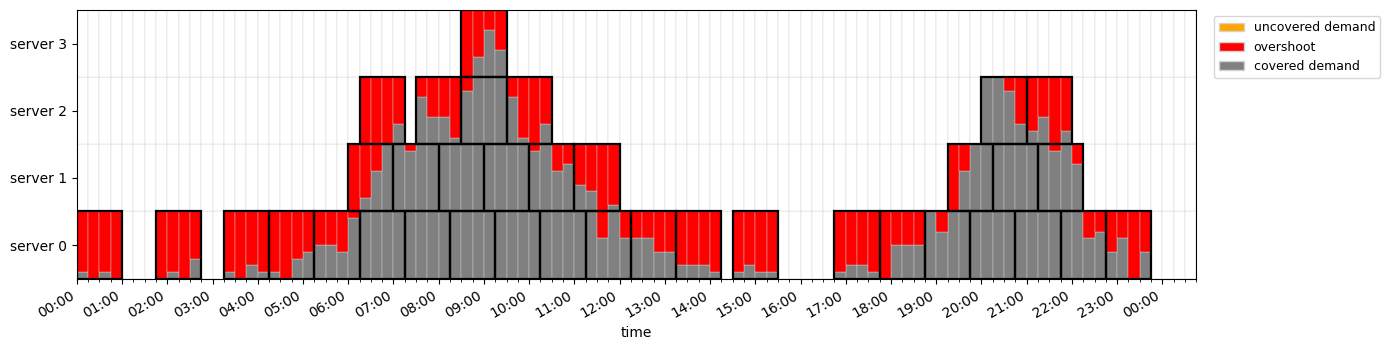

alpha=0.5 -> coverage=0.921


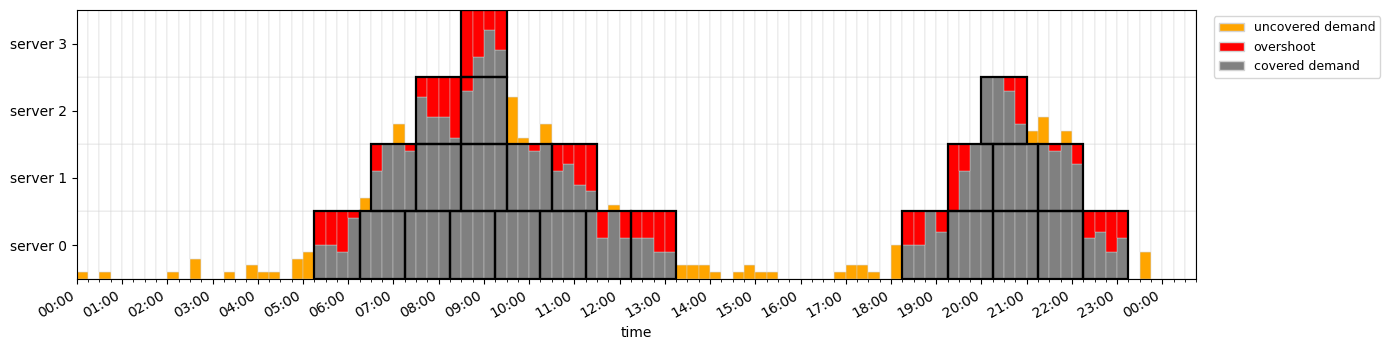

alpha=1.0 -> coverage=0.822


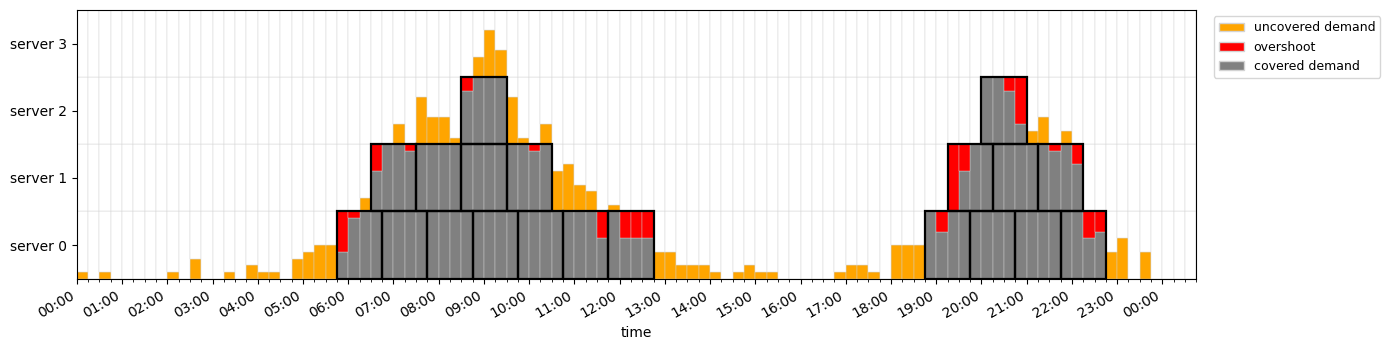

alpha=1.5 -> coverage=0.772


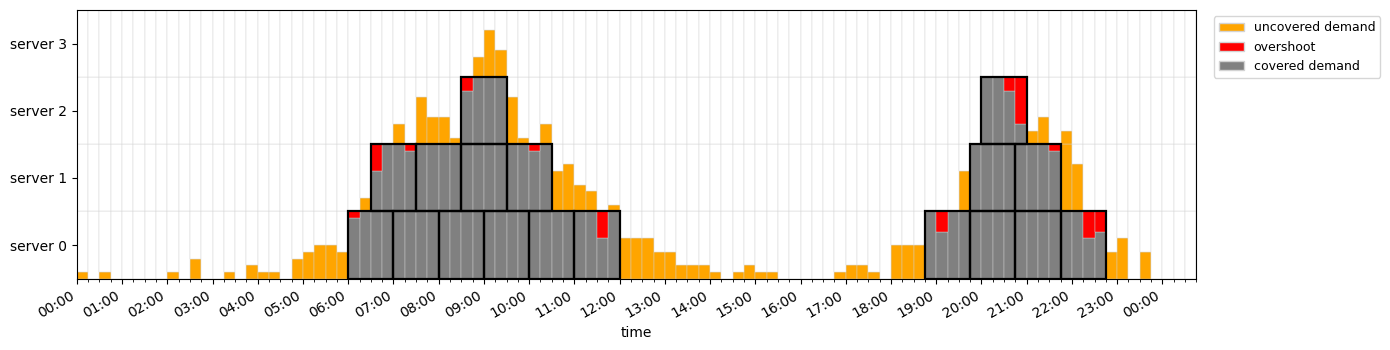

alpha=2.0 -> coverage=0.772


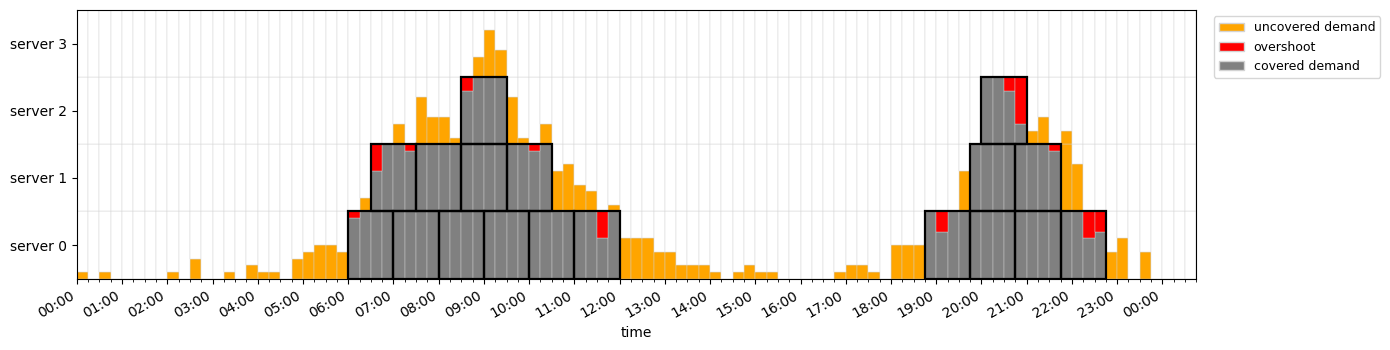

alpha=2.5 -> coverage=0.772


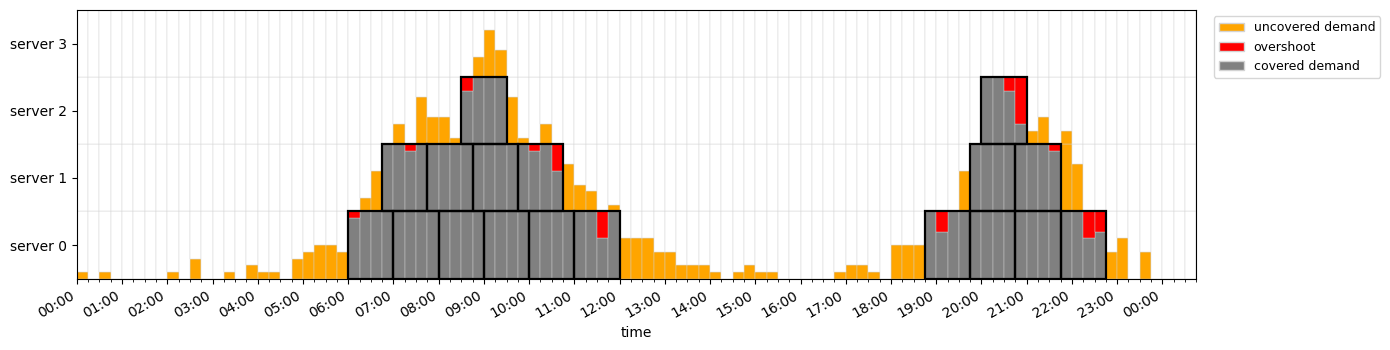

In [ ]:
results=pd.DataFrame(columns=["alpha", "coverage"])

for alpha in np.arange(0.0, 3, 0.5):

    L = 4
    curve = solve_coverage_batch(D, L, alpha, return_curve=True)

    K_total = 40
    g = allocate_budget(curve, K_total)

    sols = solve_allocated(D, L, alpha, g)

    rep = coverage_report(D, sols, L, time_values)

    results.loc[len(results)] = [alpha, rep.total.coverage]
    print(f"alpha={alpha:.1f} -> coverage={rep.total.coverage:.3f}")
    plot_grid_overlay(D, sols, time_values, L=L)


In [30]:
results

,alpha,coverage
0,0.0,1.000000
1,0.5,0.921348
2,1.0,0.822472
3,1.5,0.771910
4,2.0,0.771910
5,2.5,0.771910
